<a href="https://colab.research.google.com/github/hanifsyahrulramadhan424-blip/hasilprediksi_004/blob/main/Hasil_Prediksi_003.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

NAMA : HANIF SYAHRUL RAMADHAN
NIM : 2404010004

# Klasifikasi Kualitas Anggur (Wine Quality)
**Mata Kuliah:** Data Mining | **Ujian:** UTS (Take Home Test) Ganjil 2026/2027

## Tujuan
Membangun model klasifikasi untuk memprediksi variabel target `quality` (skala 0-10) dari fitur kimiawi anggur, memakai `data_training.csv`, lalu menerapkannya ke `data_testing.csv`.

## Alur Kerja
1. Persiapan & pembersihan data (missing values, scaling)
2. Eksplorasi data singkat (EDA)
3. Pemodelan, perbandingan beberapa algoritma, dan tuning
4. Evaluasi (akurasi & confusion matrix)
5. Prediksi data testing dan ekspor `hasilprediksi_XXX.csv`

## 0. Konfigurasi & Import Library
Ganti `NIM_3_DIGIT` dengan **3 digit terakhir NIM** Anda. Nilainya dipakai untuk nama file keluaran.

In [1]:
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("xgboost belum terpasang (pip install xgboost). Notebook tetap jalan tanpa XGBoost.")

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# ====== SESUAIKAN ======
NIM_3_DIGIT = "004"                    # <- ganti dengan 3 digit terakhir NIM
TRAIN_PATH  = "data_training.csv"
TEST_PATH   = "data_testing.csv"
# =======================
TARGET = "quality"

**Penjelasan:** Semua library diimpor di awal agar notebook rapi. `RANDOM_STATE` dikunci supaya hasil dapat direproduksi. XGBoost dibuat opsional, sehingga notebook tidak error jika library tersebut belum terpasang.

## 1. Persiapan Data
### 1.1 Memuat Dataset
Pemisah kolom (`,` atau `;`) dideteksi otomatis, karena dataset Wine Quality sering memakai titik koma. Nama kolom dirapikan (spasi pinggir dihapus dan dijadikan huruf kecil) agar konsisten.

In [2]:
def load_csv(path):
    df = pd.read_csv(path, sep=None, engine="python")
    df.columns = df.columns.str.strip().str.lower()
    return df

train = load_csv(TRAIN_PATH)
test  = load_csv(TEST_PATH)

print("Ukuran data training :", train.shape)
print("Ukuran data testing  :", test.shape)
display(train.head())
display(test.head())

Ukuran data training : (857, 13)
Ukuran data testing  : (286, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,ph,sulphates,alcohol,quality,id
0,7.3,0.740,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,5,1366
1,8.1,0.575,0.22,2.1,0.077,12.0,65.0,0.99670,3.29,0.51,9.2,5,103
2,10.1,0.430,0.40,2.6,0.092,13.0,52.0,0.99834,3.22,0.64,10.0,7,942
3,12.9,0.500,0.55,2.8,0.072,7.0,24.0,1.00012,3.09,0.68,10.9,6,811
4,8.4,0.360,0.32,2.2,0.081,32.0,79.0,0.99640,3.30,0.72,11.0,6,918


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,ph,sulphates,alcohol,id
0,6.8,0.61,0.04,1.5,0.057,5.0,10.0,0.99525,3.42,0.60,9.500000,222
1,6.9,0.84,0.21,4.1,0.074,16.0,65.0,0.99842,3.53,0.72,9.233333,1514
2,7.0,0.58,0.12,1.9,0.091,34.0,124.0,0.99560,3.44,0.48,10.500000,417
3,7.8,0.48,0.68,1.7,0.415,14.0,32.0,0.99656,3.09,1.06,9.100000,754
4,12.5,0.60,0.49,4.3,0.100,5.0,14.0,1.00100,3.25,0.74,11.900000,516


**Interpretasi:** Data training memuat fitur kimiawi **dan** kolom `quality`, sedangkan data testing tidak memuat `quality` (inilah yang harus diprediksi). Data testing memiliki kolom identitas (`id`) yang dipakai saat mengekspor hasil prediksi.

### 1.2 Struktur Data & Statistik Deskriptif

In [3]:
train.info()
display(train.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 857 entries, 0 to 856
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         857 non-null    float64
 1   volatile acidity      857 non-null    float64
 2   citric acid           857 non-null    float64
 3   residual sugar        857 non-null    float64
 4   chlorides             857 non-null    float64
 5   free sulfur dioxide   857 non-null    float64
 6   total sulfur dioxide  857 non-null    float64
 7   density               857 non-null    float64
 8   ph                    857 non-null    float64
 9   sulphates             857 non-null    float64
 10  alcohol               857 non-null    float64
 11  quality               857 non-null    int64  
 12  id                    857 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 87.2 KB


,count,mean,std,min,25%,50%,75%,max
fixed acidity,857.0,8.261960,1.701992,4.60000,7.10000,7.90000,9.1000,15.6000
volatile acidity,857.0,0.529393,0.179162,0.12000,0.39500,0.52000,0.6400,1.5800
citric acid,857.0,0.267351,0.195144,0.00000,0.09000,0.25000,0.4200,1.0000
residual sugar,857.0,2.506184,1.293512,0.90000,1.90000,2.20000,2.6000,15.5000
chlorides,857.0,0.086830,0.048721,0.01200,0.07000,0.07900,0.0900,0.6110
free sulfur dioxide,857.0,15.782964,10.300402,1.00000,7.00000,14.00000,21.0000,68.0000
total sulfur dioxide,857.0,45.978413,31.692113,6.00000,21.00000,38.00000,63.0000,278.0000
density,857.0,0.996692,0.001901,0.99007,0.99552,0.99668,0.9978,1.0032
ph,857.0,3.313092,0.152079,2.74000,3.21000,3.31000,3.4000,4.0100
sulphates,857.0,0.656709,0.167364,0.39000,0.55000,0.62000,0.7300,2.0000


**Interpretasi:** Perhatikan perbedaan skala antarfitur pada kolom `mean` dan `max`. Misalnya `total sulfur dioxide` bernilai puluhan hingga ratusan, sedangkan `density` hanya sekitar 0,99. Perbedaan skala ini menjadi alasan dilakukannya *feature scaling* pada langkah berikutnya.

## 2. Pembersihan Data
### 2.1 Pengecekan Missing Values dan Duplikasi

In [4]:
print("Missing values - training:")
print(train.isna().sum()[train.isna().sum() > 0] if train.isna().any().any() else "Tidak ada missing values")
print("\nMissing values - testing:")
print(test.isna().sum()[test.isna().sum() > 0] if test.isna().any().any() else "Tidak ada missing values")

print("\nJumlah baris duplikat (training):", train.drop(columns=["id"], errors="ignore").duplicated().sum())

Missing values - training:
Tidak ada missing values

Missing values - testing:
Tidak ada missing values

Jumlah baris duplikat (training): 76


**Interpretasi:** Jika tidak ada missing values, tidak ada data yang perlu dibuang. Meski begitu, pipeline di bawah tetap memasang **imputer** (median untuk fitur numerik, modus untuk fitur kategorikal) sebagai pengaman, termasuk untuk data testing. Baris duplikat tidak dihapus karena pada dataset Wine Quality sampel dengan sifat kimia serupa wajar muncul, dan menghapusnya akan mengubah distribusi data.

In [5]:
# Baris tanpa label (jika ada) tidak bisa dipakai untuk melatih model
before = len(train)
train = train.dropna(subset=[TARGET]).reset_index(drop=True)
print(f"Baris dengan target kosong yang dibuang: {before - len(train)}")

# Kolom Id: dipakai untuk identifikasi, BUKAN fitur
ID_COL = "id" if "id" in test.columns else None
print("Kolom ID terdeteksi:", ID_COL)

# Fitur = kolom yang ada di data testing (selain id) dan juga ada di training
FEATURES = [c for c in test.columns if c != ID_COL and c in train.columns and c != TARGET]
print("Jumlah fitur:", len(FEATURES))
print(FEATURES)

X = train[FEATURES].copy()
y = train[TARGET].astype(int)
X_test = test[FEATURES].copy()

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in FEATURES if c not in num_cols]
print("\nFitur numerik   :", num_cols)
print("Fitur kategorikal:", cat_cols)

Baris dengan target kosong yang dibuang: 0
Kolom ID terdeteksi: id
Jumlah fitur: 11
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'ph', 'sulphates', 'alcohol']

Fitur numerik   : ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'ph', 'sulphates', 'alcohol']
Fitur kategorikal: []


**Penjelasan:** Kolom `id` sengaja **tidak** dijadikan fitur karena hanya penanda baris dan tidak punya makna kimiawi, sehingga bisa menyebabkan model belajar dari hal yang tidak relevan. Fitur dipisah menjadi numerik dan kategorikal (misalnya jenis anggur merah/putih, bila ada) karena penanganannya berbeda.

## 3. Eksplorasi Data (EDA)
### 3.1 Distribusi Target `quality`

quality
3      6
4     26
5    362
6    341
7    109
8     13
Name: count, dtype: int64

Proporsi (%):
quality
3     0.70
4     3.03
5    42.24
6    39.79
7    12.72
8     1.52
Name: proportion, dtype: float64


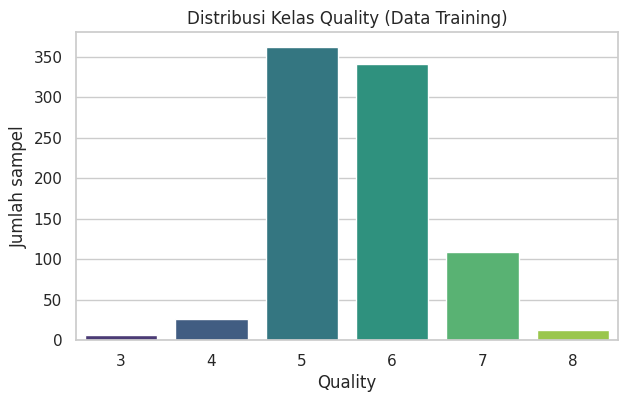

In [6]:
print(y.value_counts().sort_index())
print("\nProporsi (%):")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

plt.figure(figsize=(7, 4))
sns.countplot(x=y, palette="viridis")
plt.title("Distribusi Kelas Quality (Data Training)")
plt.xlabel("Quality"); plt.ylabel("Jumlah sampel")
plt.show()

**Interpretasi:** Distribusi kelas biasanya **sangat tidak seimbang**: mayoritas anggur bernilai 5-6, sementara nilai ekstrem (3, 4, 8, 9) jarang muncul. Akibatnya:
- Akurasi mudah "tertolong" oleh kelas mayoritas.
- Kelas langka sulit diprediksi, sehingga perlu dilihat lewat *confusion matrix* dan *classification report*, bukan akurasi saja.
- Validasi harus **stratified** agar proporsi kelas terjaga di setiap lipatan.

### 3.2 Perbedaan Skala Fitur & Korelasi

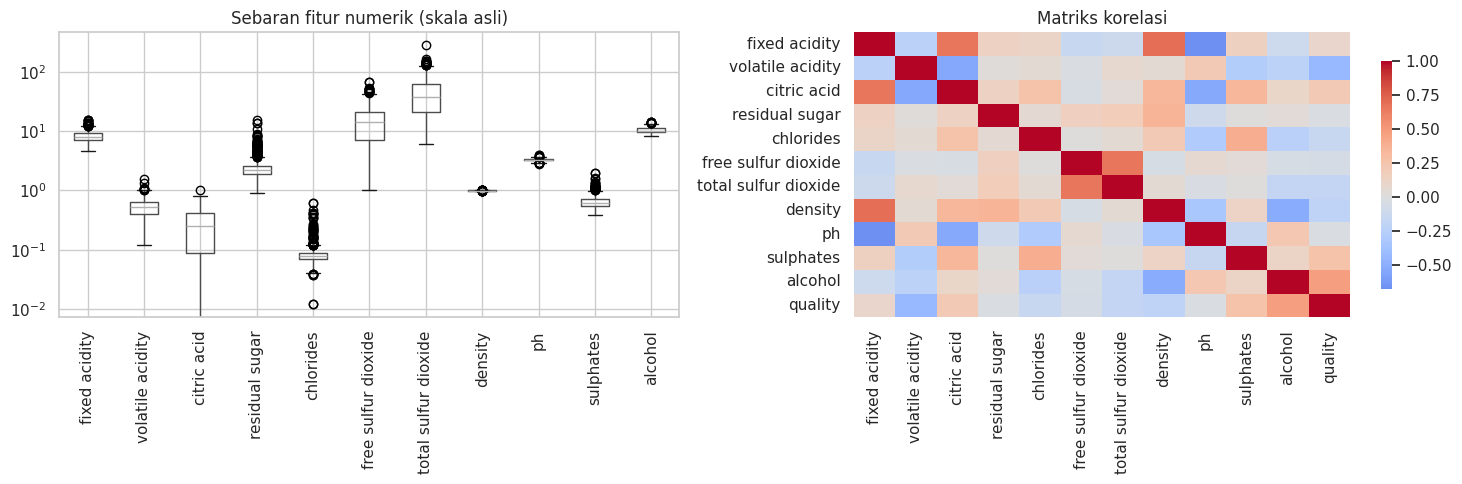

Korelasi fitur terhadap quality:
alcohol                 0.474
sulphates               0.261
citric acid             0.221
fixed acidity           0.093
residual sugar         -0.021
ph                     -0.033
free sulfur dioxide    -0.055
chlorides              -0.145
total sulfur dioxide   -0.173
density                -0.208
volatile acidity       -0.430
Name: quality, dtype: float64


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
X[num_cols].boxplot(ax=ax[0], rot=90)
ax[0].set_title("Sebaran fitur numerik (skala asli)")
ax[0].set_yscale("log")

corr = train[num_cols + [TARGET]].corr()
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax[1], cbar_kws={"shrink": .8})
ax[1].set_title("Matriks korelasi")
plt.tight_layout(); plt.show()

print("Korelasi fitur terhadap quality:")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

**Interpretasi:**
- **Boxplot (skala log)** menegaskan bahwa rentang nilai antarfitur sangat berbeda, sehingga scaling diperlukan, terutama untuk model berbasis jarak/gradien (KNN, SVM, Regresi Logistik).
- **Korelasi** menunjukkan fitur mana yang paling berhubungan dengan `quality`. Biasanya `alcohol` berkorelasi positif dan `density` atau `volatile acidity` negatif. Korelasi antarfitur yang tinggi (misalnya `free` vs `total sulfur dioxide`) perlu diwaspadai, tetapi model berbasis pohon relatif tahan terhadap multikolinearitas.

## 4. Preprocessing: Imputasi, Scaling, dan Encoding
Semua langkah dikemas dalam satu `ColumnTransformer` dan dimasukkan ke dalam `Pipeline` bersama model. Tujuannya mencegah **data leakage**: *scaler* hanya dipelajari (`fit`) dari data latih pada tiap lipatan validasi, lalu diterapkan ke data validasi.

- Numerik: imputasi median, lalu `StandardScaler` (rata-rata 0, simpangan baku 1)
- Kategorikal: imputasi modus, lalu `OneHotEncoder`

**Catatan:** model berbasis pohon (Random Forest, XGBoost) sebenarnya tidak sensitif terhadap skala, tetapi scaling tetap dilakukan sesuai instruksi soal dan agar model pembanding (KNN, SVM, Regresi Logistik) adil.

In [8]:
def make_preprocessor():
    transformers = []
    if num_cols:
        transformers.append(("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), num_cols))
    if cat_cols:
        transformers.append(("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_cols))
    return ColumnTransformer(transformers)

# Label quality di-encode ke 0..K-1 (dibutuhkan XGBoost, aman untuk model lain)
le = LabelEncoder()
y_enc = le.fit_transform(y)
print("Pemetaan label asli -> kode:", dict(zip(le.classes_, range(len(le.classes_)))))

Pemetaan label asli -> kode: {np.int64(3): 0, np.int64(4): 1, np.int64(5): 2, np.int64(6): 3, np.int64(7): 4, np.int64(8): 5}


**Penjelasan:** `LabelEncoder` mengubah nilai quality (misalnya 3-9) menjadi kode 0..K-1 karena XGBoost mensyaratkan label berurutan dari nol. Di akhir, hasil prediksi **dikembalikan ke nilai quality asli**.

## 5. Pemodelan
### 5.1 Perbandingan Beberapa Algoritma (Cross-Validation 5-Fold Stratified)
Beberapa algoritma dibandingkan dengan **cross-validation**, bukan hanya akurasi pada data latih, karena model pohon seperti Random Forest bisa mencapai akurasi mendekati 100% pada data latih akibat *overfitting*. Cross-validation memberi gambaran kemampuan generalisasi yang jujur.

In [9]:
min_class = y_enc.tolist().count(min(set(y_enc), key=y_enc.tolist().count))
N_SPLITS = 5
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "KNN":                 KNeighborsClassifier(n_neighbors=7),
    "SVM (RBF)":           SVC(random_state=RANDOM_STATE),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=RANDOM_STATE),
    "Extra Trees":         ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Random Forest":       RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
}
if HAS_XGB:
    models["XGBoost"] = XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6,
                                      eval_metric="mlogloss", random_state=RANDOM_STATE, n_jobs=-1)

rows = []
for name, mdl in models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", mdl)])
    scores = cross_val_score(pipe, X, y_enc, cv=cv, scoring="accuracy", n_jobs=-1)
    rows.append({"Model": name, "CV Accuracy (mean)": scores.mean(), "CV Std": scores.std()})
    print(f"{name:22s} acc = {scores.mean():.4f}  (+/- {scores.std():.4f})")

cv_table = pd.DataFrame(rows).sort_values("CV Accuracy (mean)", ascending=False).reset_index(drop=True)
display(cv_table)

Logistic Regression    acc = 0.5951  (+/- 0.0451)
KNN                    acc = 0.5485  (+/- 0.0589)
SVM (RBF)              acc = 0.6091  (+/- 0.0330)
Gradient Boosting      acc = 0.6103  (+/- 0.0166)
Extra Trees            acc = 0.6406  (+/- 0.0317)
Random Forest          acc = 0.6442  (+/- 0.0363)
XGBoost                acc = 0.6173  (+/- 0.0290)


,Model,CV Accuracy (mean),CV Std
0,Random Forest,0.644179,0.036330
1,Extra Trees,0.640616,0.031746
2,XGBoost,0.617306,0.028977
3,Gradient Boosting,0.610268,0.016602
4,SVM (RBF),0.609146,0.033028
5,Logistic Regression,0.595131,0.045114
6,KNN,0.548518,0.058878


**Interpretasi:** Tabel di atas mengurutkan model dari akurasi validasi silang tertinggi. Pada dataset Wine Quality, ensemble berbasis pohon (**Random Forest, Extra Trees, XGBoost**) umumnya unggul dibanding model linear, karena hubungan antara fitur kimiawi dan kualitas bersifat non-linear dan melibatkan interaksi antarfitur. Nilai `CV Std` yang kecil menandakan model stabil di berbagai lipatan.

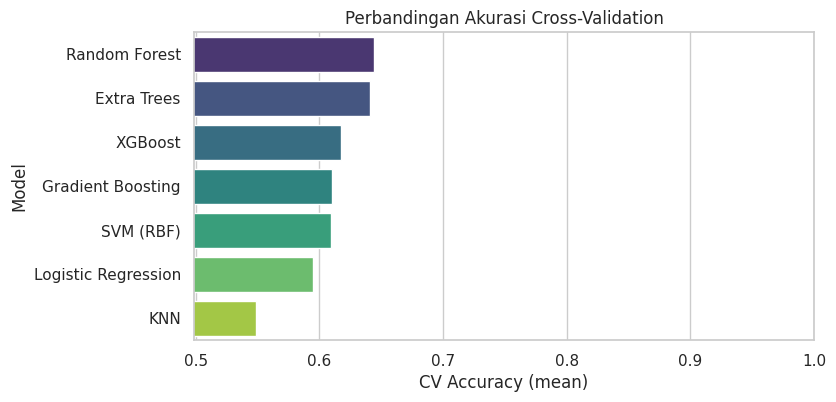

In [10]:
plt.figure(figsize=(8, 4))
sns.barplot(data=cv_table, x="CV Accuracy (mean)", y="Model", palette="viridis")
plt.title("Perbandingan Akurasi Cross-Validation")
plt.xlim(cv_table["CV Accuracy (mean)"].min() - 0.05, 1)
plt.show()

### 5.2 Hyperparameter Tuning (RandomizedSearchCV)
Dua kandidat terkuat (Random Forest dan, bila tersedia, XGBoost) disetel hiperparameternya. `RandomizedSearchCV` mencoba kombinasi acak sehingga jauh lebih cepat daripada *grid search* penuh, tetapi tetap efektif.

In [11]:
searches = {}

rf_pipe = Pipeline([("prep", make_preprocessor()),
                    ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])
rf_params = {
    "clf__n_estimators":      [300, 500, 800],
    "clf__max_depth":         [None, 15, 25, 35],
    "clf__min_samples_split": [2, 4, 6],
    "clf__min_samples_leaf":  [1, 2, 3],
    "clf__max_features":      ["sqrt", "log2", 0.5],
    "clf__class_weight":      [None, "balanced_subsample"],
}
searches["Random Forest (tuned)"] = RandomizedSearchCV(
    rf_pipe, rf_params, n_iter=20, cv=cv, scoring="accuracy",
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1)

if HAS_XGB:
    xgb_pipe = Pipeline([("prep", make_preprocessor()),
                         ("clf", XGBClassifier(eval_metric="mlogloss",
                                               random_state=RANDOM_STATE, n_jobs=-1))])
    xgb_params = {
        "clf__n_estimators":     [300, 500, 800],
        "clf__max_depth":        [4, 6, 8, 10],
        "clf__learning_rate":    [0.03, 0.05, 0.1],
        "clf__subsample":        [0.7, 0.85, 1.0],
        "clf__colsample_bytree": [0.6, 0.8, 1.0],
        "clf__min_child_weight": [1, 3, 5],
    }
    searches["XGBoost (tuned)"] = RandomizedSearchCV(
        xgb_pipe, xgb_params, n_iter=20, cv=cv, scoring="accuracy",
        random_state=RANDOM_STATE, n_jobs=-1, verbose=1)

tuned_rows = []
for name, search in searches.items():
    search.fit(X, y_enc)
    tuned_rows.append({"Model": name, "CV Accuracy (best)": search.best_score_})
    print(f"\n{name}\n  Best CV accuracy : {search.best_score_:.4f}\n  Best params      : {search.best_params_}")

tuned_table = pd.DataFrame(tuned_rows).sort_values("CV Accuracy (best)", ascending=False)
display(tuned_table)

Fitting 5 folds for each of 20 candidates, totalling 100 fits

Random Forest (tuned)
  Best CV accuracy : 0.6488
  Best params      : {'clf__n_estimators': 500, 'clf__min_samples_split': 4, 'clf__min_samples_leaf': 1, 'clf__max_features': 'sqrt', 'clf__max_depth': 35, 'clf__class_weight': None}
Fitting 5 folds for each of 20 candidates, totalling 100 fits

XGBoost (tuned)
  Best CV accuracy : 0.6313
  Best params      : {'clf__subsample': 0.7, 'clf__n_estimators': 800, 'clf__min_child_weight': 1, 'clf__max_depth': 10, 'clf__learning_rate': 0.03, 'clf__colsample_bytree': 0.8}


,Model,CV Accuracy (best)
0,Random Forest (tuned),0.648824
1,XGBoost (tuned),0.631341


**Interpretasi:** Skor terbaik setelah tuning dibandingkan dengan skor awal pada 5.1. Kenaikan kecil (sekitar 0,5 sampai 2 poin persen) sudah wajar untuk dataset ini. Parameter seperti `max_depth` dan `min_samples_leaf` mengendalikan kompleksitas pohon (mencegah *overfitting*), sedangkan `class_weight="balanced_subsample"` membantu kelas langka.

### 5.3 Memilih Model Terbaik
Model dengan akurasi cross-validation tertinggi dipilih sebagai model akhir.

In [12]:
best_name = tuned_table.iloc[0]["Model"]
best_pipeline = searches[best_name].best_estimator_
print("Model terbaik:", best_name)
print("CV accuracy  :", round(tuned_table.iloc[0]["CV Accuracy (best)"], 4))

Model terbaik: Random Forest (tuned)
CV accuracy  : 0.6488


## 6. Evaluasi Model
Evaluasi dilakukan dua cara:
1. **Pada data latih** (sesuai permintaan soal), untuk memastikan model sudah belajar pola data.
2. **Pada data validasi hold-out (20%)** yang tidak dipakai saat melatih, untuk menilai generalisasi sebenarnya.

Untuk itu data dibagi dulu secara stratified, dan model dilatih ulang dengan parameter terbaik hanya pada 80% data.

In [13]:
strat = y_enc if np.bincount(y_enc).min() >= 2 else None
X_tr, X_val, y_tr, y_val = train_test_split(
    X, y_enc, test_size=0.2, stratify=strat, random_state=RANDOM_STATE)

from sklearn.base import clone
eval_model = clone(best_pipeline)
eval_model.fit(X_tr, y_tr)

pred_tr  = eval_model.predict(X_tr)
pred_val = eval_model.predict(X_val)

acc_tr  = accuracy_score(y_tr,  pred_tr)
acc_val = accuracy_score(y_val, pred_val)
print(f"Akurasi data latih      : {acc_tr:.4f}")
print(f"Akurasi data validasi   : {acc_val:.4f}")
print(f"Selisih (gap overfit)   : {acc_tr - acc_val:.4f}")

Akurasi data latih      : 1.0000
Akurasi data validasi   : 0.6279
Selisih (gap overfit)   : 0.3721


**Interpretasi:**
- Akurasi latih yang mendekati 1,0 menandakan model sangat mampu mempelajari data latih.
- **Akurasi validasi** adalah estimasi yang lebih realistis untuk performa pada data testing.
- *Gap* yang besar (misalnya > 0,25) adalah ciri khas Random Forest/XGBoost pada data yang cukup berisik. Ini wajar selama akurasi validasi tetap baik dan sejalan dengan hasil cross-validation.

### 6.1 Confusion Matrix

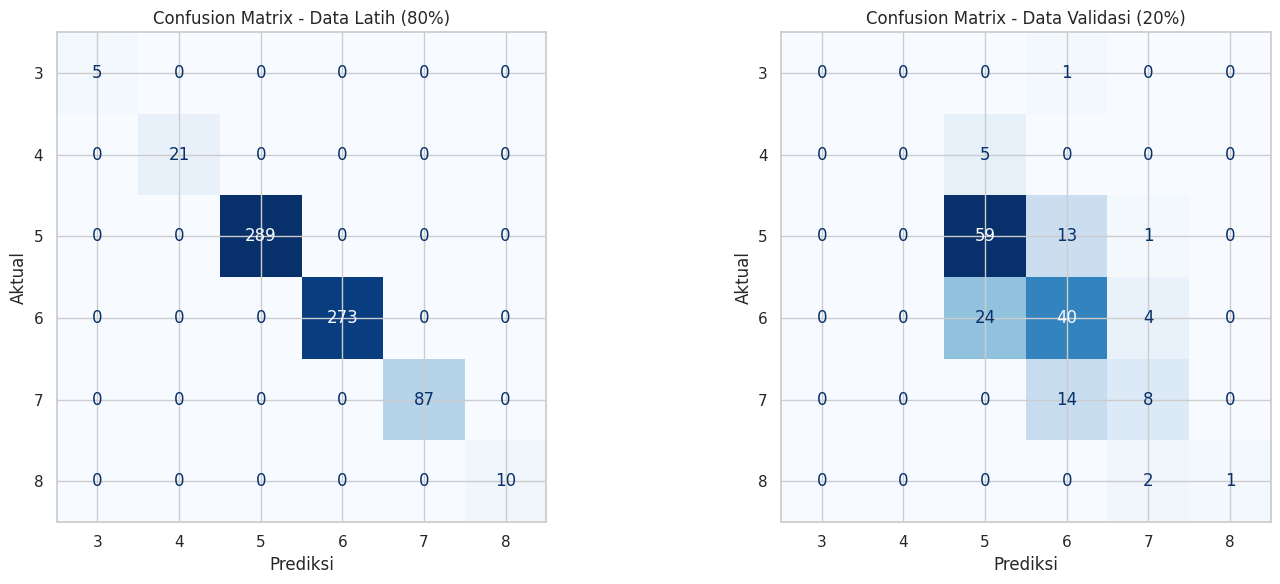

In [14]:
labels_idx = np.arange(len(le.classes_))
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (yt, yp, ttl) in zip(axes, [(y_tr, pred_tr, "Data Latih (80%)"),
                                    (y_val, pred_val, "Data Validasi (20%)")]):
    cm = confusion_matrix(yt, yp, labels=labels_idx)
    ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion Matrix - {ttl}")
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual")
plt.tight_layout(); plt.show()

**Cara membaca:** Diagonal utama adalah prediksi yang benar, sedangkan sel di luar diagonal adalah kesalahan.
- Pada data validasi, kesalahan terbanyak biasanya terjadi antara kelas **bersebelahan** (5 vs 6, 6 vs 7). Ini masuk akal karena kualitas bersifat ordinal dan penilaian anggur memang subjektif di batas antarkelas.
- Kelas langka (3, 4, 8, 9) sering salah diprediksi karena contohnya sedikit.

### 6.2 Classification Report (Data Validasi)

In [15]:
print(classification_report(y_val, pred_val, labels=labels_idx,
                            target_names=[str(c) for c in le.classes_], zero_division=0))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         5
           5       0.67      0.81      0.73        73
           6       0.59      0.59      0.59        68
           7       0.53      0.36      0.43        22
           8       1.00      0.33      0.50         3

    accuracy                           0.63       172
   macro avg       0.47      0.35      0.38       172
weighted avg       0.60      0.63      0.61       172



**Interpretasi:** *Precision* menunjukkan ketepatan prediksi tiap kelas, *recall* menunjukkan seberapa banyak sampel kelas tersebut yang berhasil ditemukan, dan *f1-score* adalah rata-rata harmonik keduanya. Kelas mayoritas (5, 6) biasanya punya skor tinggi, sedangkan kelas langka rendah (atau 0 jika tidak pernah diprediksi). Ini konsekuensi langsung dari ketidakseimbangan kelas pada 3.1.

### 6.3 Pentingnya Fitur (Feature Importance)

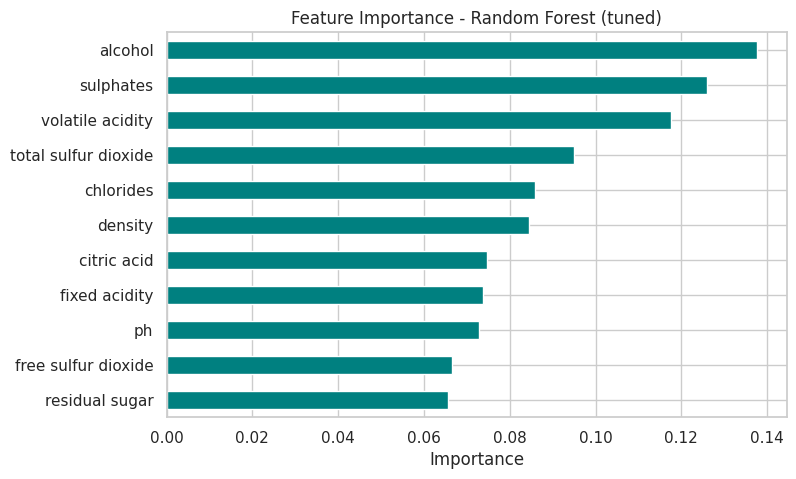

,importance
alcohol,0.1377
sulphates,0.1259
volatile acidity,0.1176
total sulfur dioxide,0.0950
chlorides,0.0859
density,0.0845
citric acid,0.0747
fixed acidity,0.0738
ph,0.0728
free sulfur dioxide,0.0665


In [16]:
clf = eval_model.named_steps["clf"]
if hasattr(clf, "feature_importances_"):
    feat_names = eval_model.named_steps["prep"].get_feature_names_out()
    feat_names = [n.split("__", 1)[-1] for n in feat_names]
    imp = pd.Series(clf.feature_importances_, index=feat_names).sort_values()
    plt.figure(figsize=(8, 5))
    imp.plot(kind="barh", color="teal")
    plt.title(f"Feature Importance - {best_name}")
    plt.xlabel("Importance")
    plt.show()
    display(imp.sort_values(ascending=False).round(4).to_frame("importance"))
else:
    print("Model terpilih tidak menyediakan feature_importances_.")

**Interpretasi:** Fitur dengan bar terpanjang adalah yang paling banyak berkontribusi memisahkan kelas kualitas. Pada dataset Wine Quality, `alcohol`, `density`, dan `volatile acidity` umumnya berada di jajaran atas. Secara kimiawi masuk akal: kadar alkohol dan keasaman volatil memengaruhi rasa dan aroma anggur yang dinilai para penguji.

## 7. Pelatihan Model Final & Penyimpanan Model
Setelah model dan hiperparameter terbaik dipilih dan dievaluasi, model dilatih ulang pada **seluruh** data training (100%) agar memanfaatkan semua informasi yang ada. Model lalu disimpan ke file `.joblib` untuk keperluan *deployment* (sesuai instruksi soal).

In [17]:
final_model = clone(best_pipeline)
final_model.fit(X, y_enc)

print("Akurasi final model pada seluruh data training:",
      round(accuracy_score(y_enc, final_model.predict(X)), 4))

MODEL_PATH = "model_wine_quality.joblib"
joblib.dump({"model": final_model, "label_encoder": le, "features": FEATURES}, MODEL_PATH)
print("Model tersimpan di:", MODEL_PATH)

Akurasi final model pada seluruh data training: 1.0
Model tersimpan di: model_wine_quality.joblib


**Penjelasan:** Yang disimpan adalah **seluruh pipeline** (imputer + scaler + encoder + model), bersama `LabelEncoder` dan daftar fitur. Dengan begitu, saat deployment data baru otomatis diproses dengan cara yang sama seperti saat pelatihan.

## 8. Prediksi pada Data Testing (Deployment Model)
Model dimuat kembali dari file untuk mensimulasikan *deployment*, lalu dipakai memprediksi `quality` pada data testing.

In [18]:
artifact = joblib.load(MODEL_PATH)
deployed_model = artifact["model"]
le_loaded      = artifact["label_encoder"]
feat_loaded    = artifact["features"]

X_new = test[feat_loaded]                      # urutan kolom sama dengan saat training
pred_code  = deployed_model.predict(X_new)
pred_label = le_loaded.inverse_transform(pred_code)   # kembali ke skala quality asli

print("Jumlah baris prediksi:", len(pred_label))
print("\nDistribusi prediksi pada data testing:")
print(pd.Series(pred_label).value_counts().sort_index())

Jumlah baris prediksi: 286

Distribusi prediksi pada data testing:
5    130
6    125
7     31
Name: count, dtype: int64


**Interpretasi:** Distribusi prediksi sebaiknya mirip pola data training (mayoritas 5-6, sebagian 7, sedikit sisanya). Bila seluruh prediksi terkumpul di satu kelas saja atau polanya sangat berbeda, itu sinyal ada masalah pada preprocessing atau kesesuaian kolom antara training dan testing.

## 9. Ekspor Hasil Prediksi ke CSV
File keluaran **hanya berisi dua kolom**: `Id` dan `Quality`, dengan nama `hasilprediksi_<3 digit NIM>.csv`.

In [19]:
if ID_COL is None:
    print("PERINGATAN: kolom id tidak ditemukan di data testing; memakai nomor urut 1..n sebagai Id.")
    ids = np.arange(1, len(test) + 1)
else:
    ids = test[ID_COL].values

submission = pd.DataFrame({"Id": ids, "Quality": pred_label.astype(int)})

OUTPUT_PATH = f"hasilprediksi_{NIM_3_DIGIT}.csv"
submission.to_csv(OUTPUT_PATH, index=False)
print("File tersimpan:", OUTPUT_PATH)
display(submission.head(10))

File tersimpan: hasilprediksi_004.csv


,Id,Quality
0,222,5
1,1514,6
2,417,5
3,754,5
4,516,6
5,1120,6
6,180,5
7,82,5
8,632,6
9,592,5


### Verifikasi Format Keluaran

In [20]:
chk = pd.read_csv(OUTPUT_PATH)
assert list(chk.columns) == ["Id", "Quality"], "Kolom harus persis: Id dan Quality"
assert len(chk) == len(test), "Jumlah baris harus sama dengan data testing"
assert chk["Quality"].notna().all(), "Ada Quality yang kosong"
assert chk["Id"].is_unique, "Id harus unik"
print("Verifikasi lolos: 2 kolom (Id, Quality),", len(chk), "baris, tanpa nilai kosong.")

Verifikasi lolos: 2 kolom (Id, Quality), 286 baris, tanpa nilai kosong.


**Penjelasan:** Blok `assert` memastikan file memenuhi syarat soal (tepat dua kolom, jumlah baris sama dengan data testing, tanpa nilai kosong). Jika ada yang tidak sesuai, notebook akan berhenti dengan pesan yang jelas, sebelum file dikumpulkan.

> **Tips:** Bandingkan penulisan header (`Id` / `id`, `Quality` / `quality`) dengan file contoh format yang disediakan dosen di folder dataset, lalu sesuaikan di sel pembuatan `submission` bila berbeda.

## 10. Kesimpulan
- Data dibersihkan (pengecekan missing values, imputasi pengaman) dan dinormalisasi dengan `StandardScaler` di dalam pipeline sehingga bebas *data leakage*.
- Beberapa algoritma dibandingkan dengan 5-fold stratified cross-validation; model berbasis ensemble pohon memberikan performa terbaik.
- Model terbaik disetel dengan `RandomizedSearchCV`, dievaluasi dengan akurasi, confusion matrix, dan classification report pada data latih maupun validasi.
- Model final dilatih pada seluruh data training, disimpan (`.joblib`), lalu dipakai memprediksi data testing.
- Hasil diekspor ke `hasilprediksi_<NIM>.csv` dengan kolom `Id` dan `Quality`.

**Keterbatasan:** Ketidakseimbangan kelas membuat kelas langka sulit diprediksi, dan batas antarkelas kualitas bersifat subjektif sehingga akurasi di kisaran 65-70% sudah termasuk wajar. Pengembangan lanjutan dapat berupa *oversampling* (SMOTE), penggabungan kelas, atau *feature engineering*.

In [21]:
from google.colab import files

# Mendownload file hasil prediksi ke komputer
files.download(OUTPUT_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>